### 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.1


## Important data-pairing safeguard

Images and masks are matched by filename stem before visualization, splitting, or training.
Do not remove this check: incorrect image–mask pairs can seriously damage segmentation performance.
The test set is kept separate from training and validation.


### 2. Project Paths

In [2]:
PROJECT_ROOT = Path("..")

SEGMENTATION_DIR = PROJECT_ROOT / "data" / "segmentation_task"

TRAIN_IMAGE_DIR = SEGMENTATION_DIR / "train" / "images"
TRAIN_MASK_DIR = SEGMENTATION_DIR / "train" / "masks"

TEST_IMAGE_DIR = SEGMENTATION_DIR / "test" / "images"
TEST_MASK_DIR = SEGMENTATION_DIR / "test" / "masks"

In [3]:
print("Segmentation directory:", SEGMENTATION_DIR)
print("Train images:", TRAIN_IMAGE_DIR)
print("Train masks:", TRAIN_MASK_DIR)
print("Test images:", TEST_IMAGE_DIR)
print("Test masks:", TEST_MASK_DIR)

Segmentation directory: ..\data\segmentation_task
Train images: ..\data\segmentation_task\train\images
Train masks: ..\data\segmentation_task\train\masks
Test images: ..\data\segmentation_task\test\images
Test masks: ..\data\segmentation_task\test\masks


In [4]:
print("Train images exists:", TRAIN_IMAGE_DIR.exists())
print("Train masks exists:", TRAIN_MASK_DIR.exists())
print("Test images exists:", TEST_IMAGE_DIR.exists())
print("Test masks exists:", TEST_MASK_DIR.exists())

Train images exists: True
Train masks exists: True
Test images exists: True
Test masks exists: True


### 3. Count Images and Masks

In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_image_files(directory):
    return sorted(
        [
            path for path in directory.iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        ]
    )

In [6]:
def get_image_files(directory):
    return sorted(
        [
            path for path in directory.iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        ]
    )


def pair_images_and_masks(image_dir, mask_dir, dataset_name):
    image_files = get_image_files(image_dir)
    mask_files = get_image_files(mask_dir)

    image_map = {path.stem: path for path in image_files}
    mask_map = {path.stem: path for path in mask_files}

    if len(image_map) != len(image_files):
        raise ValueError(f"{dataset_name}: duplicate image filename stems found.")
    if len(mask_map) != len(mask_files):
        raise ValueError(f"{dataset_name}: duplicate mask filename stems found.")

    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))

    print(f"\\n{dataset_name}")
    print("Images:", len(image_files))
    print("Masks :", len(mask_files))
    print("Images without matching masks:", len(missing_masks))
    print("Masks without matching images:", len(missing_images))

    if missing_masks or missing_images:
        raise ValueError(
            f"{dataset_name}: image/mask pairing failed. "
            f"Examples without masks: {missing_masks[:5]}; "
            f"examples without images: {missing_images[:5]}"
        )

    matched_stems = sorted(image_map)
    paired_images = [image_map[stem] for stem in matched_stems]
    paired_masks = [mask_map[stem] for stem in matched_stems]

    # Explicit safety check: every pair must share the same filename stem.
    assert all(img.stem == mask.stem for img, mask in zip(paired_images, paired_masks))

    return paired_images, paired_masks


train_images, train_masks = pair_images_and_masks(
    TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, "Training dataset"
)

test_images, test_masks = pair_images_and_masks(
    TEST_IMAGE_DIR, TEST_MASK_DIR, "Testing dataset"
)

print("\\nAll images and masks are explicitly paired by filename stem.")


\nTraining dataset
Images: 3933
Masks : 3933
Images without matching masks: 0
Masks without matching images: 0
\nTesting dataset
Images: 860
Masks : 860
Images without matching masks: 0
Masks without matching images: 0
\nAll images and masks are explicitly paired by filename stem.


### 4. Check Image-Mask Pairing

In [7]:
train_image_names = {path.stem for path in train_images}
train_mask_names = {path.stem for path in train_masks}
test_image_names = {path.stem for path in test_images}
test_mask_names = {path.stem for path in test_masks}

Check unmatched files:

In [8]:
train_images_without_masks = train_image_names - train_mask_names
train_masks_without_images = train_mask_names - train_image_names

test_images_without_masks = test_image_names - test_mask_names
test_masks_without_images = test_mask_names - test_image_names

In [9]:
print("Training images without masks:", len(train_images_without_masks))
print("Training masks without images:", len(train_masks_without_images))

print("Testing images without masks:", len(test_images_without_masks))
print("Testing masks without images:", len(test_masks_without_images))

Training images without masks: 0
Training masks without images: 0
Testing images without masks: 0
Testing masks without images: 0


File names

In [10]:
print("Sample training images:")
for path in train_images[:5]:
    print(" ", path.name)

print("\nSample training masks:")
for path in train_masks[:5]:
    print(" ", path.name)

Sample training images:
  brisc2025_train_00001_gl_ax_t1.jpg
  brisc2025_train_00002_gl_ax_t1.jpg
  brisc2025_train_00003_gl_ax_t1.jpg
  brisc2025_train_00004_gl_ax_t1.jpg
  brisc2025_train_00005_gl_ax_t1.jpg

Sample training masks:
  brisc2025_train_00001_gl_ax_t1.png
  brisc2025_train_00002_gl_ax_t1.png
  brisc2025_train_00003_gl_ax_t1.png
  brisc2025_train_00004_gl_ax_t1.png
  brisc2025_train_00005_gl_ax_t1.png


### 5. Inspect Image and Mask Dimensions

In [11]:
sample_image_path = train_images[0]
sample_mask_path = train_masks[0]

image = Image.open(sample_image_path)
mask = Image.open(sample_mask_path)

print("Image:")
print("  File:", sample_image_path.name)
print("  Size:", image.size)
print("  Mode:", image.mode)

print("\nMask:")
print("  File:", sample_mask_path.name)
print("  Size:", mask.size)
print("  Mode:", mask.mode)

Image:
  File: brisc2025_train_00001_gl_ax_t1.jpg
  Size: (512, 512)
  Mode: RGB

Mask:
  File: brisc2025_train_00001_gl_ax_t1.png
  Size: (512, 512)
  Mode: L


### 6. Visualize an MRI + Mask

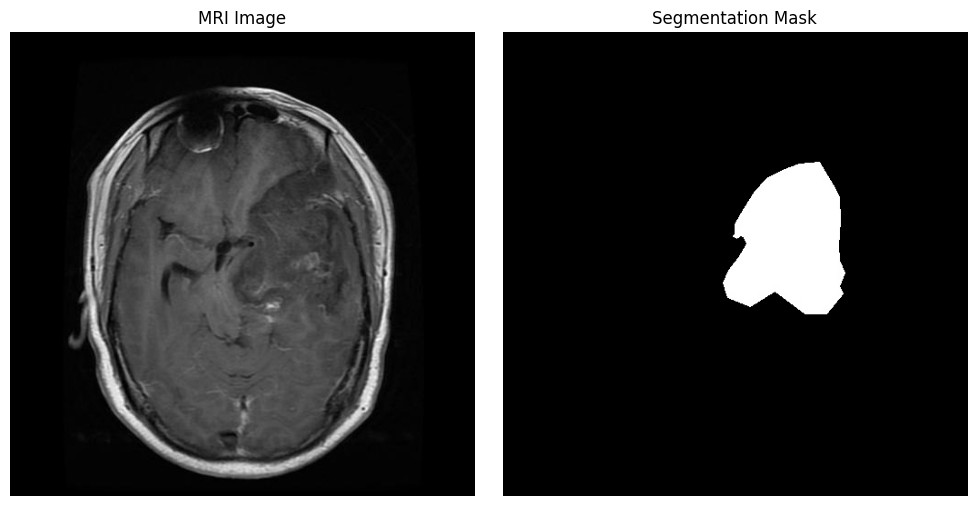

In [12]:
image_arr = np.array(image)
mask_arr = np.array(mask)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image_arr, cmap="gray")
axes[0].set_title("MRI Image")
axes[0].axis("off")

axes[1].imshow(mask_arr, cmap="gray")
axes[1].set_title("Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Also check the overlay:

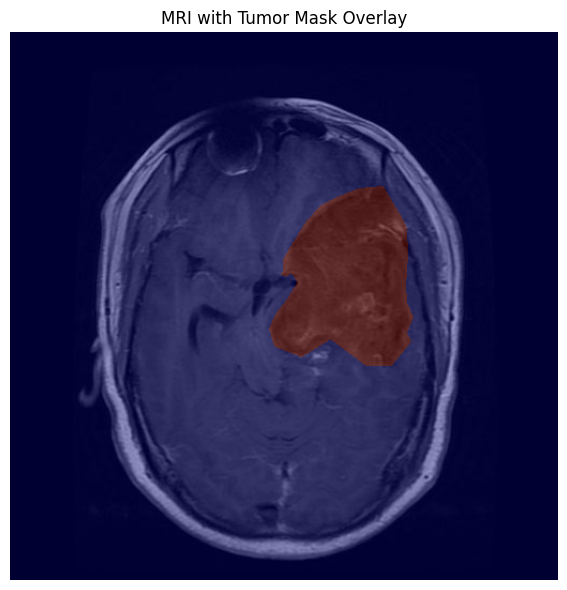

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(image_arr, cmap='gray')
ax.imshow(mask_arr, cmap="jet", alpha=0.4)

ax.set_title("MRI with Tumor Mask Overlay")
ax.axis("off")

plt.tight_layout()
plt.show()

### 7. Analyze the masks

In [14]:
unique_values = np.unique(mask_arr)

print("Unique mask values:")
print(unique_values)

print("\nNumber of unique values:", len(unique_values))

print("\nMask data type:", mask_arr.dtype)
print("Mask minimum:", mask_arr.min())
print("Mask maximum:", mask_arr.max())

Unique mask values:
[  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Number of unique values: 16

Mask data type: uint8
Mask minimum: 0
Mask maximum: 255


Check how many pixels belong to background vs tumor

In [15]:
values, counts = np.unique(mask_arr, return_counts=True)
print("Mask pixel distribution:")

for val, count in zip(values, counts):
    percentage = (count/mask_arr.size) * 100
    print(f"Value {val}: {count:,} pixels ({percentage:.2f}%)")

Mask pixel distribution:
Value 0: 244,991 pixels (93.46%)
Value 1: 398 pixels (0.15%)
Value 2: 227 pixels (0.09%)
Value 3: 117 pixels (0.04%)
Value 4: 39 pixels (0.01%)
Value 5: 20 pixels (0.01%)
Value 6: 6 pixels (0.00%)
Value 7: 1 pixels (0.00%)
Value 248: 2 pixels (0.00%)
Value 249: 2 pixels (0.00%)
Value 250: 26 pixels (0.01%)
Value 251: 44 pixels (0.02%)
Value 252: 111 pixels (0.04%)
Value 253: 220 pixels (0.08%)
Value 254: 413 pixels (0.16%)
Value 255: 15,527 pixels (5.92%)


In [16]:
sample_masks = train_masks[:20]

all_values = set()

for mask_path in sample_masks:
    mask = np.array(Image.open(mask_path))
    all_values.update(np.unique(mask))

print("Unique values found across 20 masks:")
print(sorted(all_values))

Unique values found across 20 masks:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 248, 249, 250, 251, 252, 253, 254, 255]


In [17]:
print("Mask statistics for first 10 training masks:\n")

for mask_path in train_masks[:10]:
    mask = np.array(Image.open(mask_path))

    print(
        f"{mask_path.name}: "
        f"min={mask.min()}, "
        f"max={mask.max()}, "
        f"unique_values={len(np.unique(mask))}"
    )

Mask statistics for first 10 training masks:

brisc2025_train_00001_gl_ax_t1.png: min=0, max=255, unique_values=16
brisc2025_train_00002_gl_ax_t1.png: min=0, max=255, unique_values=17
brisc2025_train_00003_gl_ax_t1.png: min=0, max=255, unique_values=14
brisc2025_train_00004_gl_ax_t1.png: min=0, max=255, unique_values=16
brisc2025_train_00005_gl_ax_t1.png: min=0, max=255, unique_values=15
brisc2025_train_00006_gl_ax_t1.png: min=0, max=255, unique_values=15
brisc2025_train_00007_gl_ax_t1.png: min=0, max=255, unique_values=16
brisc2025_train_00008_gl_ax_t1.png: min=0, max=255, unique_values=14
brisc2025_train_00009_gl_ax_t1.png: min=0, max=255, unique_values=15
brisc2025_train_00010_gl_ax_t1.png: min=0, max=255, unique_values=14


In [18]:
from collections import Counter

train_mask_extensions = Counter(
    path.suffix.lower()
    for path in train_masks
)

test_mask_extensions = Counter(
    path.suffix.lower()
    for path in test_masks
)

print("Training mask formats:", train_mask_extensions)
print("Testing mask formats:", test_mask_extensions)

Training mask formats: Counter({'.png': 3933})
Testing mask formats: Counter({'.png': 860})


### 8. Verify the binary conversion

#### Convert the sample mask

In [19]:
binary_mask = (mask_arr >= 128).astype(np.float32)

print("Original mask values:")
print(np.unique(mask_arr))

print("\nBinary mask values:")
print(np.unique(binary_mask))

print("\nBackground pixels:", np.sum(binary_mask == 0))
print("Tumor pixels:", np.sum(binary_mask == 1))

Original mask values:
[  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Binary mask values:
[0. 1.]

Background pixels: 245799
Tumor pixels: 16345


#### Compare original and binary mask

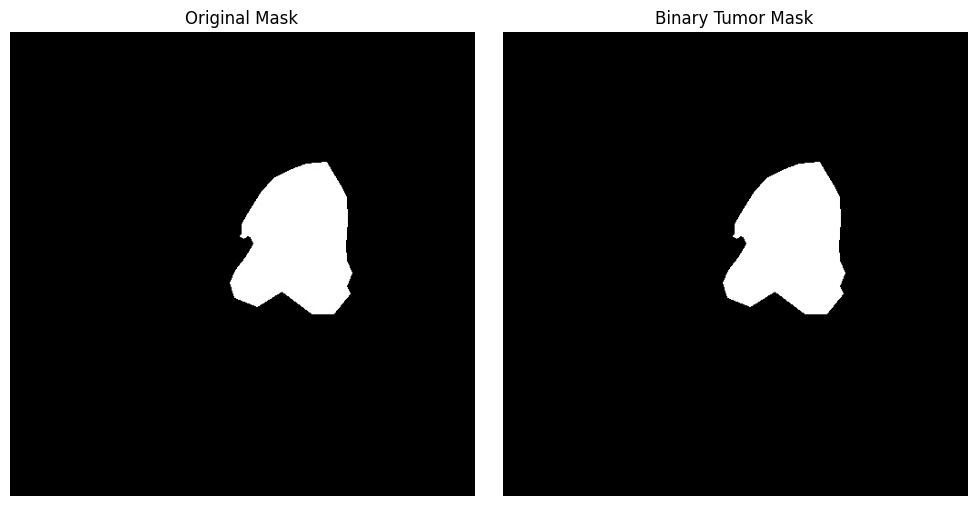

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(mask_arr, cmap="gray")
axes[0].set_title("Original Mask")
axes[0].axis("off")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Binary Tumor Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

#### Verify the binary mask over the MRI

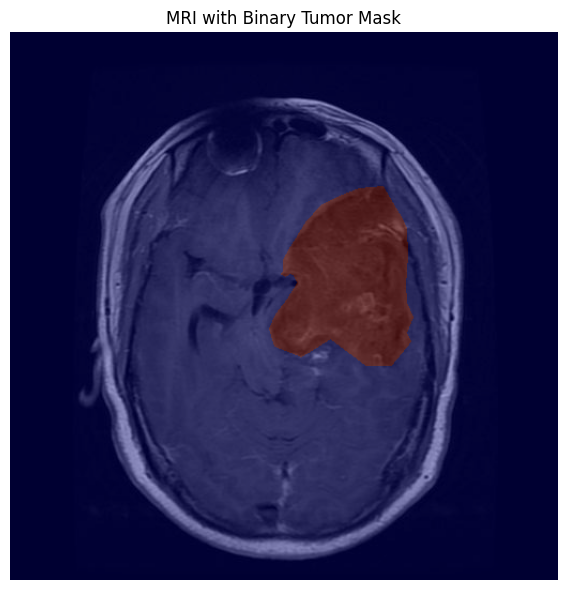

In [21]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(image_arr, cmap="gray")
ax.imshow(binary_mask, cmap="jet", alpha=0.4)

ax.set_title("MRI with Binary Tumor Mask")
ax.axis("off")

plt.tight_layout()
plt.show()

### 9. Preprocessing

MRI images are resized to 256×256 pixels and normalized to the range [0, 1].

Segmentation masks are converted to binary masks where:
- 0 represents background
- 1 represents tumor

Nearest-neighbor interpolation is used when resizing masks to preserve
their discrete segmentation labels

In [22]:
IMG_SIZE = 256

def load_and_preprocess(image_path, mask_path):

    # Convert pathlib.Path to string
    image_path = tf.convert_to_tensor(str(image_path))
    mask_path = tf.convert_to_tensor(str(mask_path))

    # Read image
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    # Read mask
    mask = tf.io.read_file(mask_path)

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    # Resize mask
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    # Convert to float32
    image = tf.cast(
        image,
        tf.float32
    )

    mask = tf.cast(
        mask,
        tf.float32
    )

    # Normalize MRI image
    image = image / 255.0

    # Convert mask to binary
    mask = tf.cast(
        mask >= 128,
        tf.float32
    )

    return image, mask

Test it on one image

In [23]:
sample_image_path = train_images[0]
sample_mask_path = train_masks[0]

processed_image, processed_mask = load_and_preprocess(
    sample_image_path,
    sample_mask_path
)

print("Image shape:", processed_image.shape)
print("Mask shape:", processed_mask.shape)

print("Image min:", tf.reduce_min(processed_image).numpy())
print("Image max:", tf.reduce_max(processed_image).numpy())

print('Mask values:', tf.unique(tf.reshape(processed_mask, [-1]))[0].numpy())

Image shape: (256, 256, 1)
Mask shape: (256, 256, 1)
Image min: 0.0
Image max: 0.9431372
Mask values: [0. 1.]


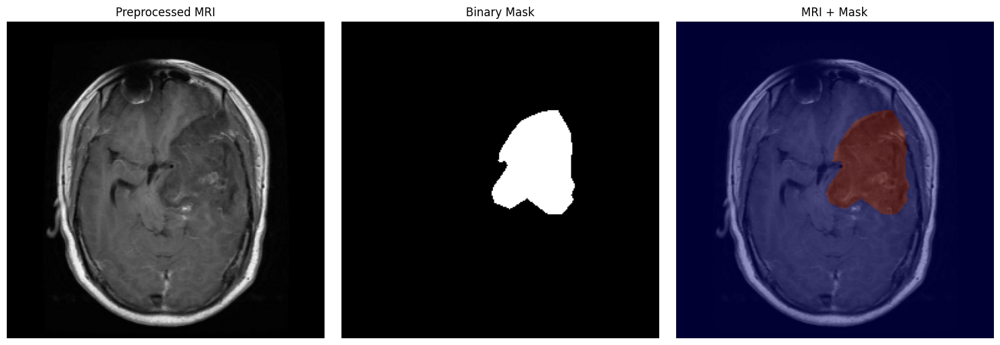

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(tf.squeeze(processed_image), cmap="gray")
axes[0].set_title("Preprocessed MRI")
axes[0].axis("off")

axes[1].imshow(tf.squeeze(processed_mask), cmap="gray")
axes[1].set_title("Binary Mask")
axes[1].axis("off")

axes[2].imshow(tf.squeeze(processed_image), cmap="gray")
axes[2].imshow(
    tf.squeeze(processed_mask),
    cmap="jet",
    alpha=0.4
)
axes[2].set_title("MRI + Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### 10. Create the Train/Validation Dataset

The original training set is divided into training and validation subsets.
The separate test set is preserved for final model evaluation.

In [25]:
from sklearn.model_selection import train_test_split

# train_images and train_masks are already matched by filename stem.
# Split the paired lists together so image/mask correspondence is preserved.
train_image_paths, val_image_paths, train_mask_paths, val_mask_paths = train_test_split(
    train_images,
    train_masks,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

assert all(img.stem == mask.stem for img, mask in zip(train_image_paths, train_mask_paths))
assert all(img.stem == mask.stem for img, mask in zip(val_image_paths, val_mask_paths))
assert all(img.stem == mask.stem for img, mask in zip(test_images, test_masks))

print("Training pairs  :", len(train_image_paths))
print("Validation pairs:", len(val_image_paths))
print("Testing pairs   :", len(test_images))
print("Pairing verification passed for train, validation, and test sets.")


Training pairs  : 3146
Validation pairs: 787
Testing pairs   : 860
Pairing verification passed for train, validation, and test sets.


#### Create the TensorFlow datasets with paired augmentation

Each MRI is loaded with its matched mask. Geometric transforms are applied to both
the MRI and mask together. Intensity augmentation is applied only to the MRI.
Augmentation is enabled for training only, never validation or testing.


In [26]:
def create_segmentation_dataset(
    image_paths,
    mask_paths,
    shuffle=False,
    batch_size=4,
    augment=False
):
    image_paths = [str(path) for path in image_paths]
    mask_paths = [str(path) for path in mask_paths]

    if len(image_paths) != len(mask_paths):
        raise ValueError("Image and mask counts do not match.")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Augmentation is explicitly enabled for training only.
    if augment:
        dataset = dataset.map(
            augment_pair,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


Use this preprocessing function for the dataset

In [27]:
def load_and_preprocess(image_path, mask_path):
    # Read grayscale MRI
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes, channels=1, expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Read mask
    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask_bytes, channels=1)

    # Resize MRI smoothly and mask with nearest-neighbor interpolation
    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE], method="bilinear"
    )
    mask = tf.image.resize(
        mask, [IMG_SIZE, IMG_SIZE], method="nearest"
    )

    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= 128, tf.float32)

    return image, mask


def augment_pair(image, mask):
    """Apply paired geometric augmentation; image-only intensity changes."""

    # Horizontal flip is applied identically to the MRI and mask.
    # For this binary segmentation task, validate that this is appropriate
    # for the dataset's orientation and intended use.
    flip = tf.random.uniform(()) > 0.5
    image = tf.cond(flip, lambda: tf.image.flip_left_right(image), lambda: image)
    mask = tf.cond(flip, lambda: tf.image.flip_left_right(mask), lambda: mask)

    # Mild intensity variation affects only the MRI, never the mask.
    image = tf.image.random_brightness(image, max_delta=0.06)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, 0.0, 1.0)

    # Keep static shapes and binary mask values.
    image = tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 1])
    mask = tf.ensure_shape(mask, [IMG_SIZE, IMG_SIZE, 1])
    mask = tf.cast(mask >= 0.5, tf.float32)

    return image, mask


#### Create the three datasets

In [28]:
BATCH_SIZE = 4

# Augmentation is enabled ONLY for the training dataset.
train_dataset = create_segmentation_dataset(
    train_image_paths,
    train_mask_paths,
    shuffle=True,
    batch_size=BATCH_SIZE,
    augment=True
)

# Validation and test data must remain unchanged.
val_dataset = create_segmentation_dataset(
    val_image_paths,
    val_mask_paths,
    shuffle=False,
    batch_size=BATCH_SIZE,
    augment=False
)

test_dataset = create_segmentation_dataset(
    test_images,
    test_masks,
    shuffle=False,
    batch_size=BATCH_SIZE,
    augment=False
)

print("Paired augmentation enabled for training only.")


Paired augmentation enabled for training only.


#### Verify the batch

In [29]:
images_batch, masks_batch = next(iter(train_dataset))

print("Images batch shape:", images_batch.shape)
print("Masks batch shape :", masks_batch.shape)

print("Image min:", tf.reduce_min(images_batch).numpy())
print("Image max:", tf.reduce_max(images_batch).numpy())

print("Mask unique values:", np.unique(masks_batch.numpy()))

Images batch shape: (4, 256, 256, 1)
Masks batch shape : (4, 256, 256, 1)
Image min: 0.0
Image max: 1.0
Mask unique values: [0. 1.]


#### Visualize a batch

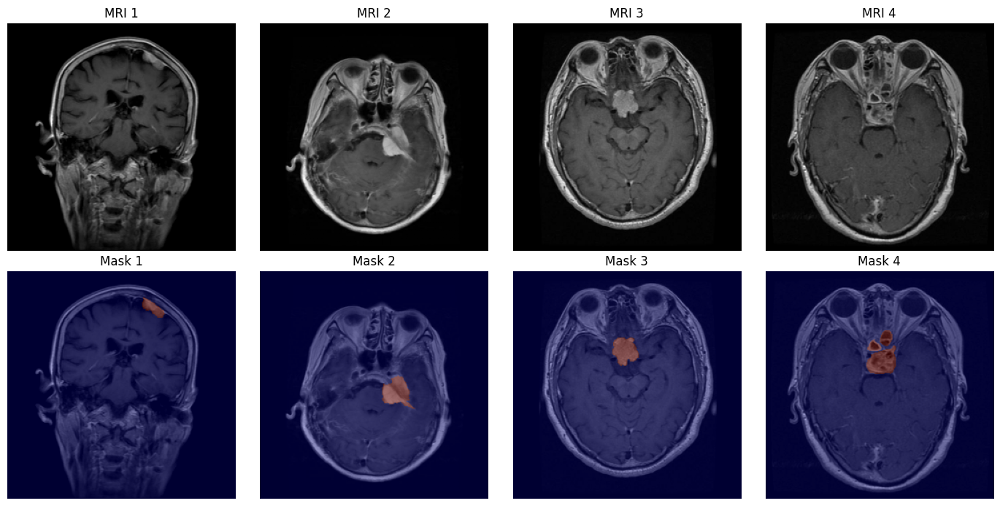

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    axes[0, i].imshow(
        tf.squeeze(images_batch[i]),
        cmap='gray'
    )

    axes[0, i].set_title(f"MRI {i+1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        tf.squeeze(images_batch[i]),
        cmap="gray"
    )

    axes[1, i].imshow(
        tf.squeeze(masks_batch[i]),
        cmap="jet",
        alpha=0.4
    )

    axes[1, i].set_title(f"Mask {i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### 11. U-Net Architecture

A U-Net encoder-decoder architecture is used for binary brain tumor
segmentation.

The encoder extracts increasingly abstract image features, while the
decoder reconstructs the spatial segmentation map.

Skip connections transfer spatial information from the encoder to the
corresponding decoder layers.

The final sigmoid output represents the probability that each pixel
belongs to the tumor.

#### Create the convolutional block

In [31]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding='same',
        kernel_initializer='he_normal'
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    return x

#### Build the U-Net

In [32]:
def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 1)):

    inputs = tf.keras.Input(shape=input_shape)

    # -------------------------
    # Encoder
    # -------------------------
    c1 = conv_block(inputs, 32)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = tf.keras.layers.MaxPooling2D((2, 2))(c4)

    # -------------------------
    # Bottleneck
    # -------------------------
    bottleneck = conv_block(p4, 512)

    # -------------------------
    # Decoder
    # -------------------------
    u6 = tf.keras.layers.Conv2DTranspose(
        256, 2, strides=2, padding='same'
    )(bottleneck)
    u6 = tf.keras.layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = tf.keras.layers.Conv2DTranspose(
        128, 2, strides=2, padding='same'
    )(c6)
    u7 = tf.keras.layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = tf.keras.layers.Conv2DTranspose(
        64, 2, strides=2, padding='same'
    )(c7)
    u8 = tf.keras.layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = tf.keras.layers.Conv2DTranspose(
        32, 2, strides=2, padding='same'
    )(c8)
    u9 = tf.keras.layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = tf.keras.layers.Conv2D(
        1, 1, activation='sigmoid'
    )(c9)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='BrainTumor_UNet'
    )

    return model


In [33]:
import gc

# Clear any previous TensorFlow model/session before building U-Net.
tf.keras.backend.clear_session()
gc.collect()


7698

#### Create the model

In [34]:
unnet_model = build_unet()
unnet_model.summary()

Model: "BrainTumor_UNet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 32  320         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 256, 32  128        ['conv2d[0][0]']                 
 alization)                     )                                                   

#### Verify the output shape

In [35]:
print("Input shape", unnet_model.input_shape)
print("Output shape", unnet_model.output_shape)

Input shape (None, 256, 256, 1)
Output shape (None, 256, 256, 1)


#### Test the model with one batch

In [36]:
sample_predictions = unnet_model(images_batch)

print('Input batch shape: ', images_batch.shape)
print('Prediction shape: ', sample_predictions.shape)

Input batch shape:  (4, 256, 256, 1)
Prediction shape:  (4, 256, 256, 1)


In [37]:
print(
    "Prediction range:",
    float(tf.reduce_min(sample_predictions)),
    "to",
    float(tf.reduce_max(sample_predictions))
)

Prediction range: 0.3528289198875427 to 0.6268478035926819


#### Visualize an untrained prediction

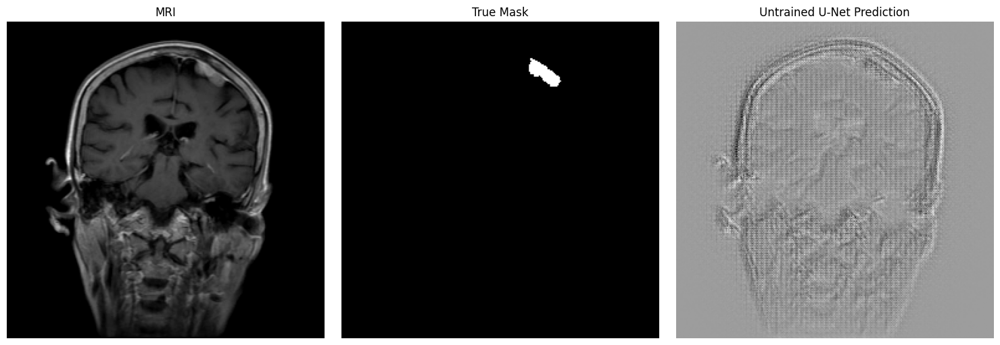

In [38]:
sample_prediction = sample_predictions[0].numpy().squeeze()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(
    images_batch[0].numpy().squeeze(),
    cmap="gray"
)
axes[0].set_title("MRI")
axes[0].axis("off")

axes[1].imshow(
    masks_batch[0].numpy().squeeze(),
    cmap="gray"
)
axes[1].set_title("True Mask")
axes[1].axis("off")

axes[2].imshow(
    sample_prediction,
    cmap="gray"
)
axes[2].set_title("Untrained U-Net Prediction")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 12. Loss Function and Evaluation Metrics

Because tumor pixels occupy a relatively small portion of each MRI,
segmentation accuracy alone is not sufficient.

The Dice coefficient and Intersection over Union (IoU) are used to
measure overlap between the predicted tumor region and the ground-truth
segmentation mask.

The training loss combines Binary Cross-Entropy and Dice Loss.

In [39]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Compute Dice independently for each image, then average the batch.
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])

    intersection = tf.reduce_sum(y_true * y_pred, axis=1)
    denominator = tf.reduce_sum(y_true, axis=1) + tf.reduce_sum(y_pred, axis=1)

    dice_per_image = (2.0 * intersection + smooth) / (denominator + smooth)
    return tf.reduce_mean(dice_per_image)


#### Dice loss

In [40]:
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)

#### Combined loss

In [41]:
def combine_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)

    bce = tf.reduce_mean(bce)

    dice = dice_loss(y_true, y_pred)

    return bce + dice

#### IoU metric

In [42]:
def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    # Compute IoU independently for each image, then average the batch.
    y_true = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])

    intersection = tf.reduce_sum(y_true * y_pred, axis=1)
    union = (
        tf.reduce_sum(y_true, axis=1)
        + tf.reduce_sum(y_pred, axis=1)
        - intersection
    )

    iou_per_image = (intersection + smooth) / (union + smooth)
    return tf.reduce_mean(iou_per_image)


### 13. Compile the U-Net

In [43]:
unnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=combine_loss,
    metrics=[
        dice_coefficient,
        iou_score
    ]
)

In [44]:
unnet_model.optimizer.learning_rate.numpy()

1e-04

### 14. Test the loss and metrics before training

In [45]:
test_loss = combine_loss(
    masks_batch,
    sample_predictions
)

test_dice = dice_coefficient(
    masks_batch,
    sample_predictions
)

test_iou = iou_score(
    masks_batch,
    sample_predictions
)

print("Initial loss :", float(test_loss))
print("Initial Dice :", float(test_dice))
print("Initial IoU  :", float(test_iou))

Initial loss : 1.6589124202728271
Initial Dice : 0.020915698260068893
Initial IoU  : 0.010220486670732498


### 15. Train the U-Net

In [46]:
MODEL_DIR = PROJECT_ROOT / "models" / "segmentation"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "unet_best.keras"

print("Model will be saved to:")
print(BEST_MODEL_PATH)

Model will be saved to:
..\models\segmentation\unet_best.keras


#### Training callbacks

In [47]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coefficient",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

#### Why these are important
ModelCheckpoint:
Saves the best U-Net rather than simply the model from the final epoch.

EarlyStopping:
Stops training if validation Dice stops improving.

ReduceLROnPlateau:
If learning gets stuck, the learning rate is reduced automatically.

In [48]:
print(
    "GPU:",
    tf.config.list_physical_devices("GPU")
)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [49]:
# GPU/memory smoke test: train on one batch before starting full training.
images_batch, masks_batch = next(iter(train_dataset))

train_on_batch_result = unnet_model.train_on_batch(
    images_batch,
    masks_batch
)

print('Train-on-batch result:', train_on_batch_result)


Train-on-batch result: [1.574470043182373, 0.046187467873096466, 0.03583907335996628]


#### Train

In [50]:
EPOCHS = 30

history = unnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
787/787 [==============================] - ETA: 0s - loss: 1.0503 - dice_coefficient: 0.1282 - iou_score: 0.3305
Epoch 1: val_dice_coefficient improved from -inf to 0.20375, saving model to ..\models\segmentation\unet_best.keras
787/787 [==============================] - 93s 117ms/step - loss: 1.0503 - dice_coefficient: 0.1282 - iou_score: 0.3305 - val_loss: 0.8864 - val_dice_coefficient: 0.2037 - val_iou_score: 0.5178 - lr: 1.0000e-04
Epoch 2/30
787/787 [==============================] - ETA: 0s - loss: 0.7353 - dice_coefficient: 0.3280 - iou_score: 0.5359
Epoch 2: val_dice_coefficient improved from 0.20375 to 0.42628, saving model to ..\models\segmentation\unet_best.keras
787/787 [==============================] - 89s 113ms/step - loss: 0.7353 - dice_coefficient: 0.3280 - iou_score: 0.5359 - val_loss: 0.6192 - val_dice_coefficient: 0.4263 - val_iou_score: 0.5563 - lr: 1.0000e-04
Epoch 3/30
787/787 [==============================] - ETA: 0s - loss: 0.4924 - dice_coefficient

### 16. Load the best saved U-Net checkpoint

In [51]:
if not BEST_MODEL_PATH.exists():
    raise FileExistsError(
        f'Checkpoint not found: {BEST_MODEL_PATH.resolve()}'
    )

unnet_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

# Compile for final evaluation
unnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combine_loss,
    metrics=[dice_coefficient, iou_score]
)

print("Best U-Net checkpoint loaded successfully.")
print("Input shape :", unnet_model.input_shape)
print("Output shape:", unnet_model.output_shape)
print("Checkpoint  :", BEST_MODEL_PATH.resolve())

Best U-Net checkpoint loaded successfully.
Input shape : (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
Checkpoint  : C:\Projects\BrainTumorAI\models\segmentation\unet_best.keras


### 17. Evaluate on the test set

In [52]:
test_results = unnet_model.evaluate(
    test_dataset,
    verbose=1,
    return_dict=True
)

print('\nFinal Test Results')

for metric_name, value in test_results.items():
    print(f'{metric_name}: {value:.4f}')

215/215 [==============================] - 14s 61ms/step - loss: 0.1724 - dice_coefficient: 0.8499 - iou_score: 0.7832

Final Test Results
loss: 0.1724
dice_coefficient: 0.8499
iou_score: 0.7832


### 18. visualize actual test predictions

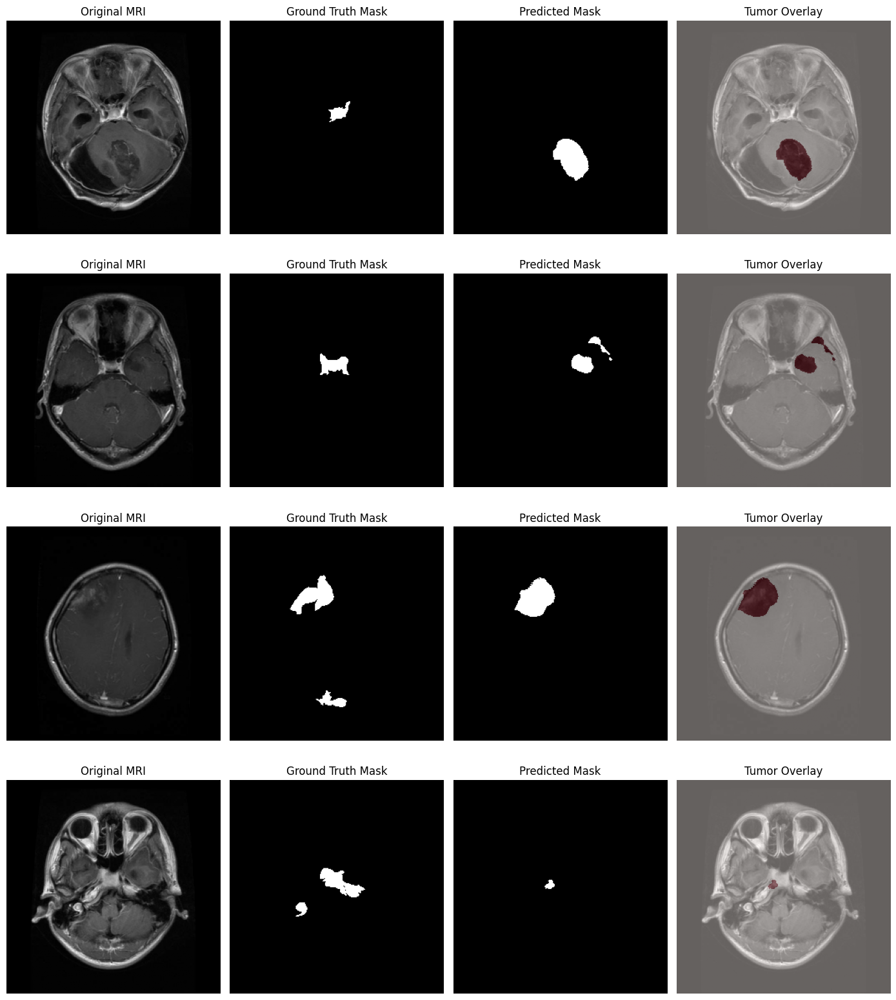

In [53]:
images, masks = next(iter(test_dataset))

# Predict tumor masks
predictions = unnet_model.predict(images, verbose=0)


# Display up to 4 test examples
num_examples = min(4, len(images))

fig, axes = plt.subplots(
    num_examples, 4,
    figsize=(14, 4 * num_examples)
)

if num_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_examples):
    image = images[i].numpy().squeeze()
    true_mask = masks[i].numpy().squeeze()
    predicted_mask = (
        predictions[i].squeeze() >= 0.5
    ).astype(np.uint8)

    # Overlay tumor prediction on the MRI
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted Mask")

    axes[i, 3].imshow(image, cmap="gray")
    axes[i, 3].imshow(
        predicted_mask,
        cmap="Reds",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[i, 3].set_title("Tumor Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [54]:
import numpy as np

def calculate_binary_dice(y_true, y_pred, smooth=1e-7):
    y_true = np.asarray(y_true).astype(bool)
    y_pred = np.asarray(y_pred).astype(bool)

    intersection = np.logical_and(y_true, y_pred).sum()
    return (
        2.0 * intersection + smooth
    ) / (
        y_true.sum() + y_pred.sum() + smooth
    )


def calculate_binary_iou(y_true, y_pred, smooth=1e-7):
    y_true = np.asarray(y_true).astype(bool)
    y_pred = np.asarray(y_pred).astype(bool)

    intersection = np.logical_and(y_true, y_pred).sum()
    union = np.logical_or(y_true, y_pred).sum()

    return (intersection + smooth) / (union + smooth)


all_dice = []
all_iou = []

for images, masks in test_dataset:
    predictions = unnet_model.predict(images, verbose=0)

    true_masks = masks.numpy() >= 0.5
    predicted_masks = predictions >= 0.5

    for true_mask, predicted_mask in zip(
        true_masks, predicted_masks
    ):
        all_dice.append(
            calculate_binary_dice(true_mask, predicted_mask)
        )
        all_iou.append(
            calculate_binary_iou(true_mask, predicted_mask)
        )

all_dice = np.array(all_dice)
all_iou = np.array(all_iou)

print(f"Number of test images: {len(all_dice)}")
print(f"Mean per-image Dice:   {all_dice.mean():.4f}")
print(f"Median per-image Dice: {np.median(all_dice):.4f}")
print(f"Mean per-image IoU:    {all_iou.mean():.4f}")
print(f"Median per-image IoU:  {np.median(all_iou):.4f}")
print(f"Images with Dice < 0.5: {(all_dice < 0.5).sum()}")

Number of test images: 860
Mean per-image Dice:   0.8527
Median per-image Dice: 0.9361
Mean per-image IoU:    0.7832
Median per-image IoU:  0.8799
Images with Dice < 0.5: 58


The median Dice of 92.10% is higher than the mean Dice of 82.42%. This indicates that the distribution of scores is affected by lower-performing images. The 87 images below 0.5 Dice deserve closer inspection.

### 19. inspect the worst predictions

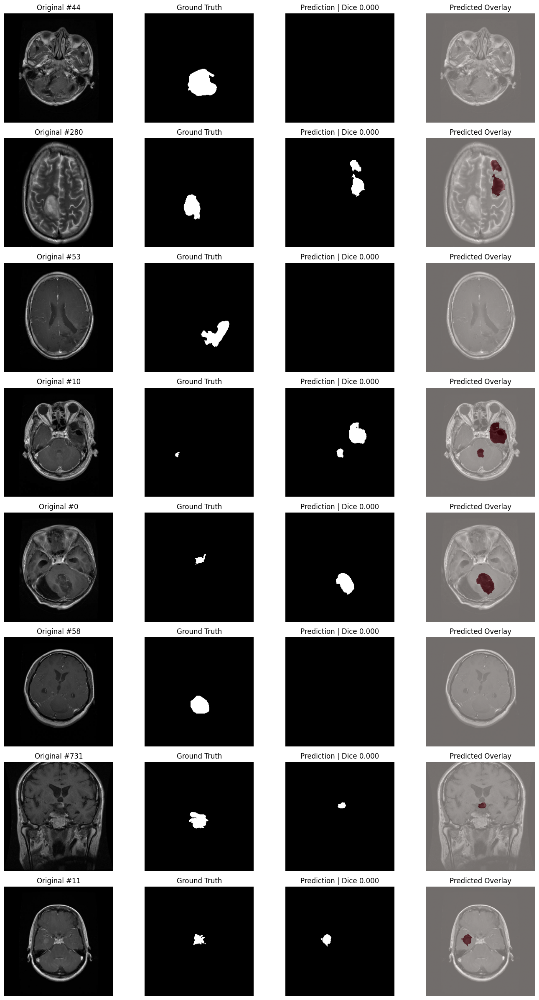

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Indices of the 8 lowest-Dice test images
worst_indices = np.argsort(all_dice)[:8]

# Recreate predictions in test-set order
test_images_all = []
test_masks_all = []
test_predictions_all = []

for images, masks in test_dataset:
    predictions = unnet_model.predict(images, verbose=0)

    test_images_all.extend(images.numpy())
    test_masks_all.extend(masks.numpy())
    test_predictions_all.extend(predictions)

test_images_all = np.asarray(test_images_all)
test_masks_all = np.asarray(test_masks_all)
test_predictions_all = np.asarray(test_predictions_all)

fig, axes = plt.subplots(8, 4, figsize=(14, 24))

for row, idx in enumerate(worst_indices):
    image = test_images_all[idx].squeeze()
    true_mask = test_masks_all[idx].squeeze() >= 0.5
    pred_mask = test_predictions_all[idx].squeeze() >= 0.5

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"Original #{idx}")

    axes[row, 1].imshow(true_mask, cmap="gray")
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(pred_mask, cmap="gray")
    axes[row, 2].set_title(f"Prediction | Dice {all_dice[idx]:.3f}")

    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(
        pred_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1
    )
    axes[row, 3].set_title("Predicted Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [56]:
# Inspect probability values for one failed test example
idx = int(worst_indices[0])

prob_map = test_predictions_all[idx].squeeze()
true_mask = test_masks_all[idx].squeeze() >= 0.5

print("Test image index:", idx)
print("Ground-truth tumor pixels:", int(true_mask.sum()))
print("Maximum predicted probability:", float(prob_map.max()))
print("Mean predicted probability:", float(prob_map.mean()))
print("Predicted pixels at threshold 0.5:",
      int((prob_map >= 0.5).sum()))

Test image index: 44
Ground-truth tumor pixels: 3157
Maximum predicted probability: 0.0055244737304747105
Mean predicted probability: 1.7295700672548264e-05
Predicted pixels at threshold 0.5: 0


see how the same example changes at different thresholds.

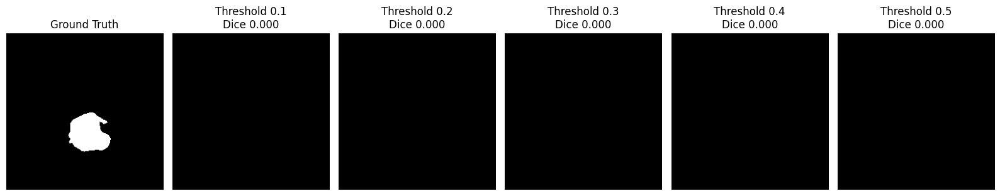

In [57]:
import matplotlib.pyplot as plt
import numpy as np

idx = int(worst_indices[0])
prob_map = test_predictions_all[idx].squeeze()
true_mask = test_masks_all[idx].squeeze()

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

fig, axes = plt.subplots(1, len(thresholds) + 1, figsize=(16, 4))

axes[0].imshow(true_mask, cmap="gray")
axes[0].set_title("Ground Truth")

for ax, threshold in zip(axes[1:], thresholds):
    pred_mask = (prob_map >= threshold).astype(np.uint8)
    dice = calculate_binary_dice(true_mask, pred_mask)

    ax.imshow(pred_mask, cmap="gray")
    ax.set_title(f"Threshold {threshold}\nDice {dice:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### 20. compare training and test predictions

TRAINING EXAMPLE
Image range: 0.07687302 0.9753047
Mask values: [0. 1.]
Tumor pixels: 3625
Prediction range: 1.7766638e-08 0.999931
Predicted pixels >= 0.5: 3725

FAILED TEST EXAMPLE
Image range: 0.0 0.95980394
Mask values: [0. 1.]
Tumor pixels: 3157
Prediction range: 1.2467864e-08 0.0055244737
Predicted pixels >= 0.5: 0


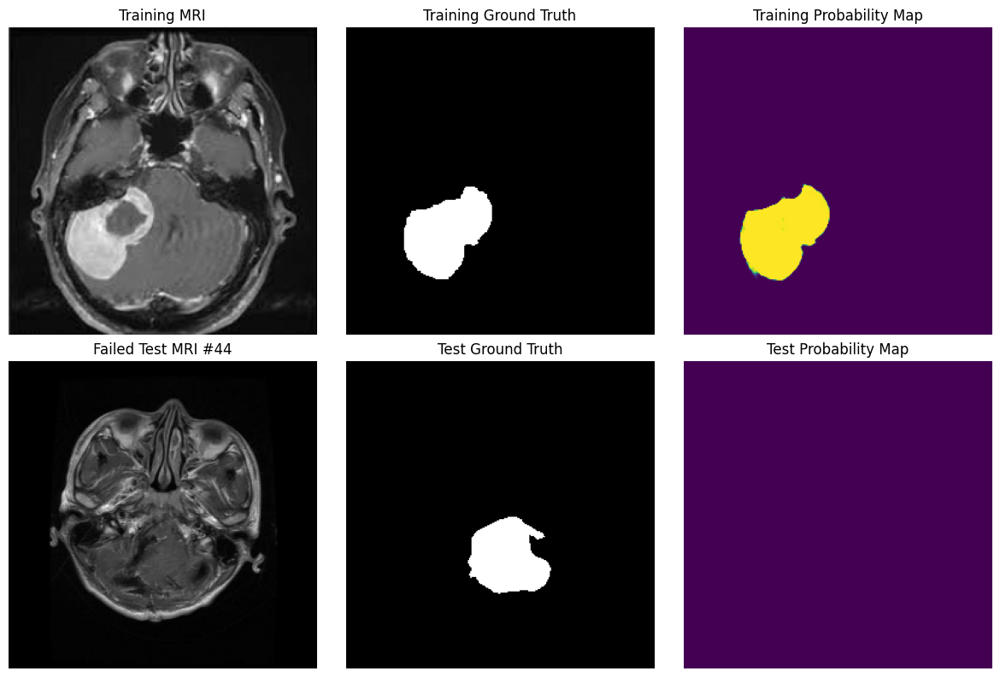

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Get one training batch
train_images, train_masks = next(iter(train_dataset))

# Compare one training image with failed test image #44
train_prob = unnet_model.predict(train_images[:1], verbose=0)[0].squeeze()
train_image = train_images[0].numpy().squeeze()
train_mask = train_masks[0].numpy().squeeze()

idx = int(worst_indices[0])
test_image = test_images_all[idx].squeeze()
test_mask = test_masks_all[idx].squeeze()
test_prob = test_predictions_all[idx].squeeze()

print("TRAINING EXAMPLE")
print("Image range:", train_image.min(), train_image.max())
print("Mask values:", np.unique(train_mask))
print("Tumor pixels:", int((train_mask >= 0.5).sum()))
print("Prediction range:", train_prob.min(), train_prob.max())
print("Predicted pixels >= 0.5:", int((train_prob >= 0.5).sum()))

print("\nFAILED TEST EXAMPLE")
print("Image range:", test_image.min(), test_image.max())
print("Mask values:", np.unique(test_mask))
print("Tumor pixels:", int((test_mask >= 0.5).sum()))
print("Prediction range:", test_prob.min(), test_prob.max())
print("Predicted pixels >= 0.5:", int((test_prob >= 0.5).sum()))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes[0, 0].imshow(train_image, cmap="gray")
axes[0, 0].set_title("Training MRI")

axes[0, 1].imshow(train_mask, cmap="gray")
axes[0, 1].set_title("Training Ground Truth")

axes[0, 2].imshow(train_prob, cmap="viridis", vmin=0, vmax=1)
axes[0, 2].set_title("Training Probability Map")

axes[1, 0].imshow(test_image, cmap="gray")
axes[1, 0].set_title("Failed Test MRI #44")

axes[1, 1].imshow(test_mask, cmap="gray")
axes[1, 1].set_title("Test Ground Truth")

axes[1, 2].imshow(test_prob, cmap="viridis", vmin=0, vmax=1)
axes[1, 2].set_title("Test Probability Map")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 21. compare preprocessing

In [59]:
import numpy as np

def inspect_batch(name, images, masks):
    images = images.numpy()
    masks = masks.numpy()

    print(f"\n{name}")
    print("Image shape:", images.shape)
    print("Image range:", images.min(), images.max())
    print("Image mean:", images.mean())
    print("Mask unique values:", np.unique(masks))
    print("Tumor pixels in first mask:",
          int((masks[0] >= 0.5).sum()))

train_images, train_masks = next(iter(train_dataset))
test_images, test_masks = next(iter(test_dataset))

inspect_batch("TRAINING BATCH", train_images, train_masks)
inspect_batch("TEST BATCH", test_images, test_masks)


TRAINING BATCH
Image shape: (4, 256, 256, 1)
Image range: 0.0 1.0
Image mean: 0.19023857
Mask unique values: [0. 1.]
Tumor pixels in first mask: 1065

TEST BATCH
Image shape: (4, 256, 256, 1)
Image range: 0.0 0.9745098
Image mean: 0.1000345
Mask unique values: [0. 1.]
Tumor pixels in first mask: 286


### 22. inspect predictions across the training set

Training image 0: Dice=0.956, max probability=1.0000
Training image 1: Dice=0.976, max probability=1.0000
Training image 2: Dice=0.961, max probability=1.0000
Training image 3: Dice=0.850, max probability=1.0000


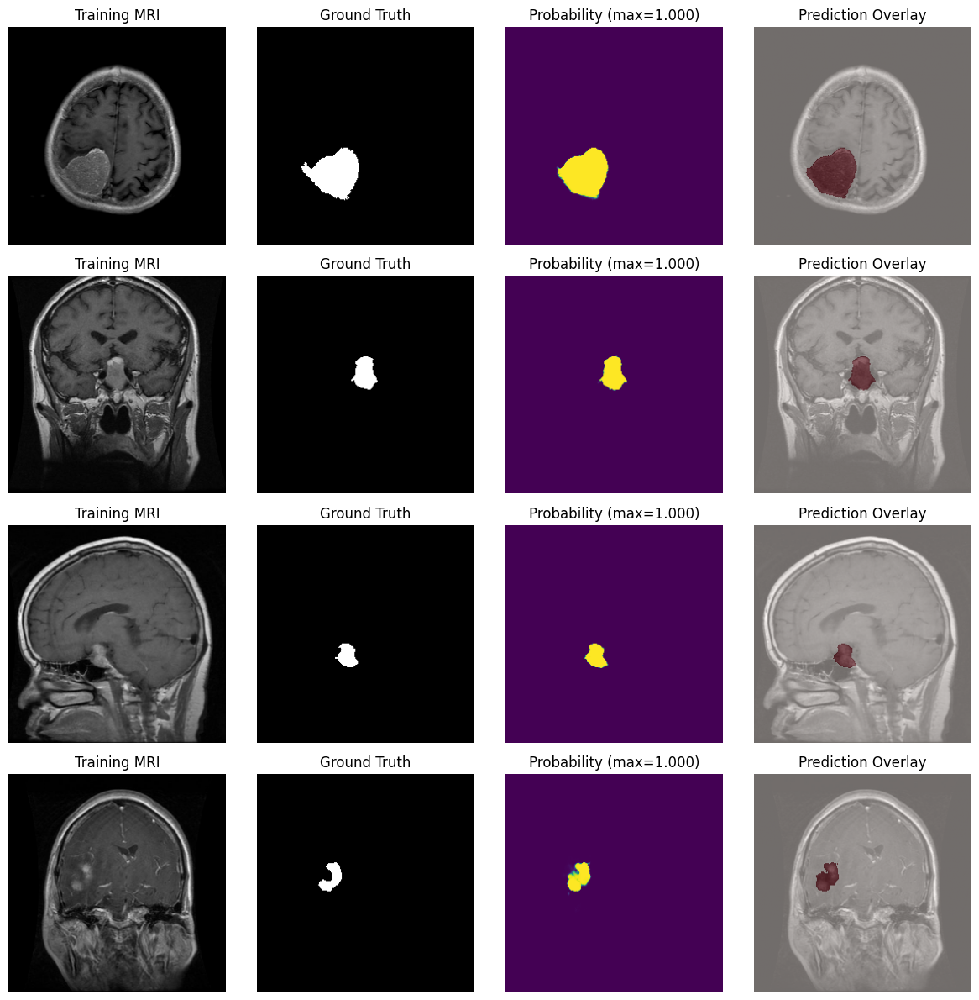

In [60]:
import matplotlib.pyplot as plt
import numpy as np

# Take a batch from the training dataset
images, masks = next(iter(train_dataset))
predictions = unnet_model.predict(images, verbose=0)

fig, axes = plt.subplots(len(images), 4, figsize=(12, 3 * len(images)))

for i in range(len(images)):
    image = images[i].numpy().squeeze()
    mask = masks[i].numpy().squeeze()
    probability = predictions[i].squeeze()
    pred_mask = probability >= 0.5

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("Training MRI")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(probability, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title(
        f"Probability (max={probability.max():.3f})"
    )

    axes[i, 3].imshow(image, cmap="gray")
    axes[i, 3].imshow(pred_mask, cmap="Reds", alpha=0.45)
    axes[i, 3].set_title("Prediction Overlay")

    for ax in axes[i]:
        ax.axis("off")

    print(
        f"Training image {i}: "
        f"Dice={calculate_binary_dice(mask >= 0.5, pred_mask):.3f}, "
        f"max probability={probability.max():.4f}"
    )

plt.tight_layout()
plt.show()

### 23. plot training and validation metrics

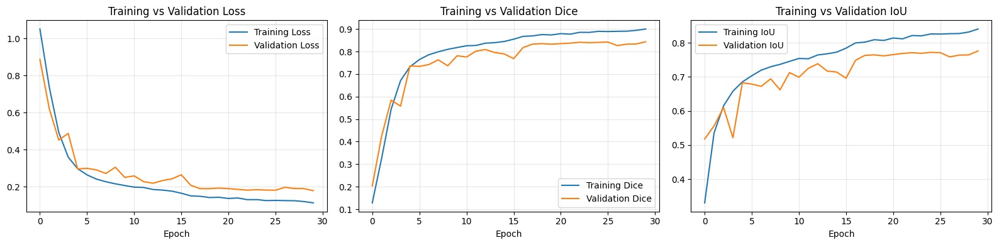

In [61]:
import matplotlib.pyplot as plt

history_dict = history.history

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
axes[0].plot(history_dict["loss"], label="Training Loss")
axes[0].plot(history_dict["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Dice
axes[1].plot(
    history_dict["dice_coefficient"],
    label="Training Dice"
)
axes[1].plot(
    history_dict["val_dice_coefficient"],
    label="Validation Dice"
)
axes[1].set_title("Training vs Validation Dice")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# IoU
axes[2].plot(history_dict["iou_score"], label="Training IoU")
axes[2].plot(history_dict["val_iou_score"], label="Validation IoU")
axes[2].set_title("Training vs Validation IoU")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:
import numpy as np
import matplotlib.pyplot as plt

# Collect test images, masks, and model probabilities
test_images_all = []
test_masks_all = []
test_probs_all = []

for images, masks in test_dataset:
    probs = unnet_model.predict(images, verbose=0)

    test_images_all.extend(images.numpy())
    test_masks_all.extend(masks.numpy())
    test_probs_all.extend(probs)

test_images_all = np.asarray(test_images_all)
test_masks_all = np.asarray(test_masks_all)
test_probs_all = np.asarray(test_probs_all)

# Calculate diagnostics for every test image
diagnostics = []

for i in range(len(test_images_all)):
    true_mask = test_masks_all[i].squeeze() >= 0.5
    prob = test_probs_all[i].squeeze()
    pred_mask = prob >= 0.5

    intersection = np.logical_and(true_mask, pred_mask).sum()
    denom = true_mask.sum() + pred_mask.sum()

    dice = 2 * intersection / denom if denom else 1.0

    diagnostics.append({
        "index": i,
        "true_pixels": int(true_mask.sum()),
        "predicted_pixels": int(pred_mask.sum()),
        "max_probability": float(prob.max()),
        "mean_probability": float(prob.mean()),
        "dice": float(dice)
    })

# Show the 10 worst test cases
worst = sorted(diagnostics, key=lambda x: x["dice"])[:10]

for item in worst:
    print(item)

{'index': 0, 'true_pixels': 286, 'predicted_pixels': 1357, 'max_probability': 0.9999817609786987, 'mean_probability': 0.020753711462020874, 'dice': 0.0}
{'index': 4, 'true_pixels': 295, 'predicted_pixels': 0, 'max_probability': 0.0014239378506317735, 'mean_probability': 7.206873306131456e-06, 'dice': 0.0}
{'index': 6, 'true_pixels': 199, 'predicted_pixels': 492, 'max_probability': 0.9996495246887207, 'mean_probability': 0.007482016924768686, 'dice': 0.0}
{'index': 9, 'true_pixels': 210, 'predicted_pixels': 0, 'max_probability': 0.00957674253731966, 'mean_probability': 2.5510280465823598e-05, 'dice': 0.0}
{'index': 10, 'true_pixels': 77, 'predicted_pixels': 1753, 'max_probability': 0.9989776611328125, 'mean_probability': 0.026363398879766464, 'dice': 0.0}
{'index': 11, 'true_pixels': 461, 'predicted_pixels': 400, 'max_probability': 0.9999042749404907, 'mean_probability': 0.006232098210602999, 'dice': 0.0}
{'index': 44, 'true_pixels': 3157, 'predicted_pixels': 0, 'max_probability': 0.005

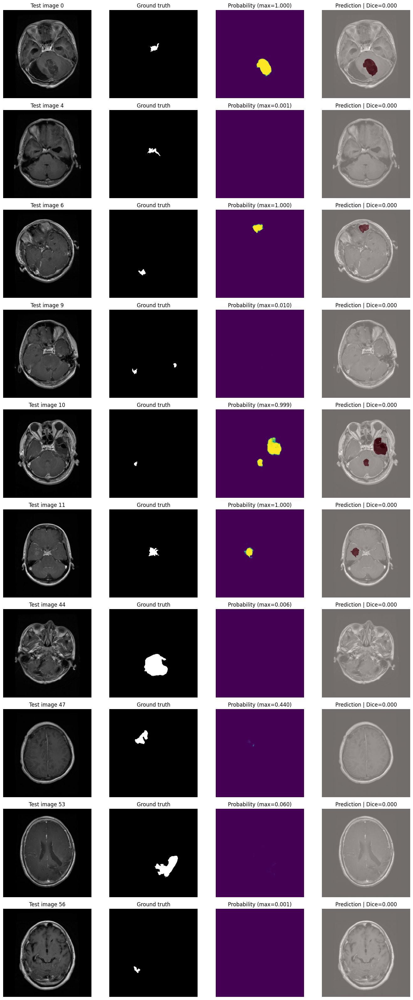

In [63]:
import numpy as np
import matplotlib.pyplot as plt

failed_indices = [0, 4, 6, 9, 10, 11, 44, 47, 53, 56]

fig, axes = plt.subplots(
    len(failed_indices), 4,
    figsize=(14, 3.2 * len(failed_indices))
)

for row, idx in enumerate(failed_indices):
    image = test_images_all[idx].squeeze()
    true_mask = test_masks_all[idx].squeeze() >= 0.5
    prob = test_probs_all[idx].squeeze()
    pred_mask = prob >= 0.5

    dice = (
        2 * np.logical_and(true_mask, pred_mask).sum()
        / (true_mask.sum() + pred_mask.sum())
        if true_mask.sum() + pred_mask.sum() > 0
        else 1.0
    )

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"Test image {idx}")

    axes[row, 1].imshow(true_mask, cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[row, 2].set_title(
        f"Probability (max={prob.max():.3f})"
    )

    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(
        pred_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1
    )
    axes[row, 3].set_title(f"Prediction | Dice={dice:.3f}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [64]:
print("First 10 image-mask pairs:")

for i, (image_path, mask_path) in enumerate(
    zip(test_images, test_masks)
):
    if i == 10:
        break

    print(f"\nPair {i}")
    print("Image:", image_path)
    print("Mask: ", mask_path)

First 10 image-mask pairs:

Pair 0
Image: tf.Tensor(
[[[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 ...

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]], shape=(256, 256, 1), dtype=float32)
Mask:  tf.Tensor(
[[[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 ...

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]], shape=(256, 256, 1), dtype=float32)

Pair 1
Image: tf.Tensor(
[[[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 ...

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0

In [65]:
# Find variables that may contain the original paths
for name, value in globals().copy().items():
    if "path" in name.lower() and (
        isinstance(value, (list, tuple))
        or hasattr(value, "__len__")
    ):
        try:
            if len(value) > 0:
                print(
                    name,
                    "| type:", type(value).__name__,
                    "| length:", len(value),
                    "| first item:", str(value[0])[:180]
                )
        except (TypeError, KeyError, IndexError):
            pass

mask_path | type: EagerTensor | length: 256 | first item: tf.Tensor(
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 
train_image_paths | type: list | length: 3146 | first item: ..\data\segmentation_task\train\images\brisc2025_train_03706_pi_ax_t1.jpg
val_image_paths | type: list | length: 787 | first item: ..\data\segmentation_task\train\images\brisc2025_train_01836_me_co_t1.jpg
train_mask_paths | type: list | length: 3146 | first item: ..\data\segmentation_task\train\masks\brisc2025_train_03706_pi_ax_t1.png
val_mask_paths | type: list | length: 787 | first item: ..\data\segmentation_task\train\masks\brisc2025_train_01836_me_co_t1.png
image_path | type: EagerTensor | length: 256 | first item: tf.Tensor(
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0

In [66]:
from pathlib import Path

def check_image_mask_pairs(image_paths, mask_paths, split_name):
    image_map = {
        Path(p).stem: str(p)
        for p in image_paths
    }
    mask_map = {
        Path(p).stem: str(p)
        for p in mask_paths
    }

    image_stems = set(image_map)
    mask_stems = set(mask_map)

    missing_masks = sorted(image_stems - mask_stems)
    missing_images = sorted(mask_stems - image_stems)

    print(f"\n{split_name} pairing report")
    print("-" * 40)
    print("Images:", len(image_paths))
    print("Masks:", len(mask_paths))
    print("Unique image stems:", len(image_stems))
    print("Unique mask stems:", len(mask_stems))
    print("Images without matching masks:", len(missing_masks))
    print("Masks without matching images:", len(missing_images))

    if missing_masks:
        print("Examples of missing masks:", missing_masks[:5])
    if missing_images:
        print("Examples of missing images:", missing_images[:5])

    return not missing_masks and not missing_images

train_pairs_ok = check_image_mask_pairs(
    train_image_paths, train_mask_paths, "Training"
)

val_pairs_ok = check_image_mask_pairs(
    val_image_paths, val_mask_paths, "Validation"
)

print("\nAll checked pairs match:", train_pairs_ok and val_pairs_ok)


Training pairing report
----------------------------------------
Images: 3146
Masks: 3146
Unique image stems: 3146
Unique mask stems: 3146
Images without matching masks: 0
Masks without matching images: 0

Validation pairing report
----------------------------------------
Images: 787
Masks: 787
Unique image stems: 787
Unique mask stems: 787
Images without matching masks: 0
Masks without matching images: 0

All checked pairs match: True


In [67]:
for name, value in globals().copy().items():
    if "test" in name.lower() and "path" in name.lower():
        if isinstance(value, (list, tuple)):
            print(
                name,
                "| count:", len(value),
                "| first:", value[0] if value else "empty"
            )

In [68]:
import inspect

print(inspect.getsource(load_and_preprocess))

def load_and_preprocess(image_path, mask_path):
    # Read grayscale MRI
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes, channels=1, expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Read mask
    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask_bytes, channels=1)

    # Resize MRI smoothly and mask with nearest-neighbor interpolation
    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE], method="bilinear"
    )
    mask = tf.image.resize(
        mask, [IMG_SIZE, IMG_SIZE], method="nearest"
    )

    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= 128, tf.float32)

    return image, mask



In [69]:
from PIL import Image
from pathlib import Path

for i in [0, 10, 100, 500, 1000]:
    image_path = Path(train_image_paths[i])
    mask_path = Path(train_mask_paths[i])

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(mask_path) as msk:
        mask_size = msk.size

    print(f"\nPair {i}")
    print("Image:", image_path.name, image_size)
    print("Mask: ", mask_path.name, mask_size)
    print("Original dimensions match:", image_size == mask_size)


Pair 0
Image: brisc2025_train_03706_pi_ax_t1.jpg (512, 512)
Mask:  brisc2025_train_03706_pi_ax_t1.png (512, 512)
Original dimensions match: True

Pair 10
Image: brisc2025_train_01396_me_ax_t1.jpg (825, 993)
Mask:  brisc2025_train_01396_me_ax_t1.png (825, 993)
Original dimensions match: True

Pair 100
Image: brisc2025_train_01996_me_co_t1.jpg (512, 512)
Mask:  brisc2025_train_01996_me_co_t1.png (512, 512)
Original dimensions match: True

Pair 500
Image: brisc2025_train_01252_me_ax_t1.jpg (507, 605)
Mask:  brisc2025_train_01252_me_ax_t1.png (507, 605)
Original dimensions match: True

Pair 1000
Image: brisc2025_train_01405_me_ax_t1.jpg (512, 512)
Mask:  brisc2025_train_01405_me_ax_t1.png (512, 512)
Original dimensions match: True


In [73]:

def load_and_preprocess(image_path, mask_path):
    # Convert pathlib.Path objects to strings
    image_path = str(image_path)
    mask_path = str(mask_path)

    # Read grayscale MRI
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Read tumor mask
    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask_bytes, channels=1)
    mask.set_shape([None, None, 1])

    # Preserve aspect ratio and pad to IMG_SIZE
    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE,
        method="bilinear"
    )
    mask = tf.image.resize_with_pad(
        mask, IMG_SIZE, IMG_SIZE,
        method="nearest"
    )

    # Normalize MRI and binarize mask
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= 128, tf.float32)

    return image, mask


In [74]:
image, mask = load_and_preprocess(
    train_image_paths[10],
    train_mask_paths[10]
)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image range:",
      float(tf.reduce_min(image)),
      float(tf.reduce_max(image)))
print("Mask values:", tf.unique(
    tf.reshape(mask, [-1])
).y.numpy())

Image shape: (256, 256, 1)
Mask shape: (256, 256, 1)
Image range: 0.0 1.0
Mask values: [0. 1.]


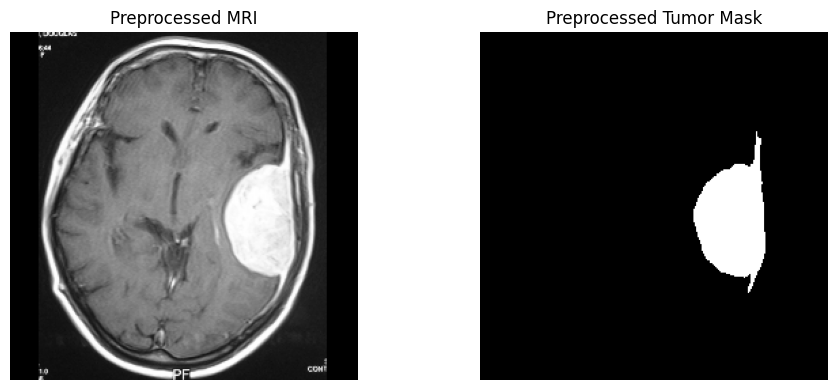

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image.numpy().squeeze(), cmap="gray")
plt.title("Preprocessed MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.numpy().squeeze(), cmap="gray")
plt.title("Preprocessed Tumor Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

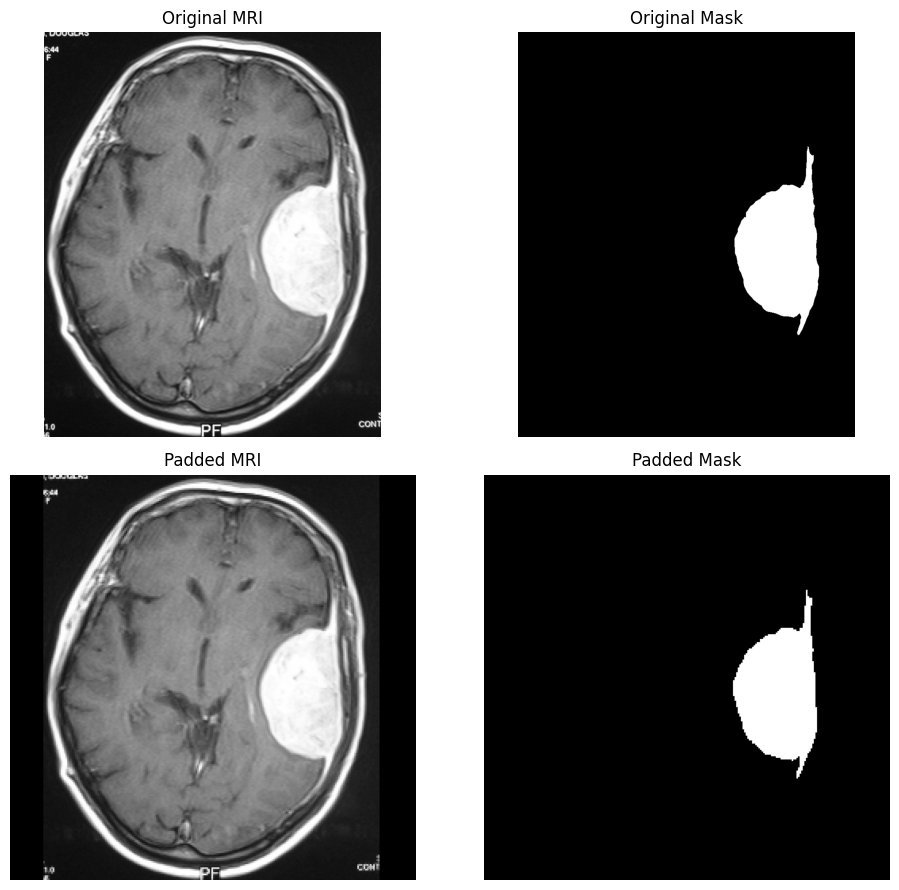

Original MRI dimensions: (993, 825)
Original mask dimensions: (993, 825)
Original mask values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Processed tumor pixels: 3629


In [76]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

i = 10

# Load original files
with Image.open(train_image_paths[i]) as im:
    original_image = np.array(im.convert("L"))

with Image.open(train_mask_paths[i]) as im:
    original_mask = np.array(im.convert("L"))

# Processed versions from the TensorFlow function
processed_image, processed_mask = load_and_preprocess(
    train_image_paths[i],
    train_mask_paths[i]
)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

axes[0, 0].imshow(original_image, cmap="gray")
axes[0, 0].set_title("Original MRI")

axes[0, 1].imshow(original_mask, cmap="gray")
axes[0, 1].set_title("Original Mask")

axes[1, 0].imshow(processed_image.numpy().squeeze(), cmap="gray")
axes[1, 0].set_title("Padded MRI")

axes[1, 1].imshow(processed_mask.numpy().squeeze(), cmap="gray")
axes[1, 1].set_title("Padded Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original MRI dimensions:", original_image.shape)
print("Original mask dimensions:", original_mask.shape)
print("Original mask values:", np.unique(original_mask)[:20])
print("Processed tumor pixels:",
      int(tf.reduce_sum(processed_mask).numpy()))


In [77]:

import tensorflow as tf

def augment_pair(image, mask):
    # Paired horizontal flip
    flip = tf.random.uniform(()) > 0.5
    image = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(image),
        lambda: image
    )
    mask = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(mask),
        lambda: mask
    )

    # Small paired rotation using TensorFlow Addons is avoided here.
    # Use only flips for now unless you already have a tested
    # paired-rotation implementation installed.

    # Mild brightness change affects MRI only, never the mask.
    image = tf.image.random_brightness(image, max_delta=0.05)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask


In [78]:
BATCH_SIZE = 4

train_dataset = train_dataset.map(
    augment_pair,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [79]:
# Inspect one batch after augmentation
images_batch, masks_batch = next(iter(train_dataset))

print("Image batch shape:", images_batch.shape)
print("Mask batch shape:", masks_batch.shape)

print(
    "Image range:",
    float(tf.reduce_min(images_batch)),
    float(tf.reduce_max(images_batch))
)

print(
    "Mask values:",
    tf.unique(tf.reshape(masks_batch, [-1])).y.numpy()
)

Image batch shape: (4, 256, 256, 1)
Mask batch shape: (4, 256, 256, 1)
Image range: 0.000199832022190094 1.0
Mask values: [0. 1.]


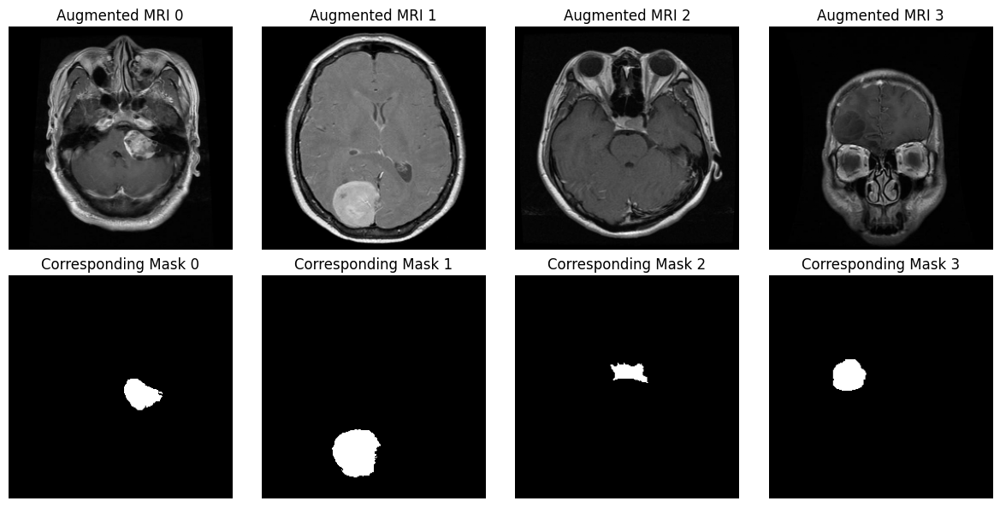

In [80]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(
        images_batch[i].numpy().squeeze(),
        cmap="gray"
    )
    axes[0, i].set_title(f"Augmented MRI {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        masks_batch[i].numpy().squeeze(),
        cmap="gray"
    )
    axes[1, i].set_title(f"Corresponding Mask {i}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [81]:
val_images_batch, val_masks_batch = next(iter(val_dataset))

print("Validation image shape:", val_images_batch.shape)
print("Validation mask shape:", val_masks_batch.shape)
print(
    "Validation mask values:",
    tf.unique(tf.reshape(val_masks_batch, [-1])).y.numpy()
)

Validation image shape: (4, 256, 256, 1)
Validation mask shape: (4, 256, 256, 1)
Validation mask values: [0. 1.]


In [82]:
import tensorflow as tf
import gc

tf.keras.backend.clear_session()
gc.collect()

unnet_model = build_unet(input_shape=(256, 256, 1))

unnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combine_loss,
    metrics=[dice_coefficient, iou_score]
)

unnet_model.summary()

Model: "BrainTumor_UNet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 32  320         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 256, 32  128        ['conv2d[0][0]']                 
 alization)                     )                                                   

In [83]:
from pathlib import Path

NEW_MODEL_PATH = Path("../models/segmentation/unet_augmented_best.keras")
NEW_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

callbacks_aug = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(NEW_MODEL_PATH),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [84]:
EPOCHS = 40

history_aug = unnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_aug,
    verbose=1
)

Epoch 1/40
786/787 [============================>.] - ETA: 0s - loss: 1.1120 - dice_coefficient: 0.1059 - iou_score: 0.3018
Epoch 1: val_dice_coefficient improved from -inf to 0.16879, saving model to ..\models\segmentation\unet_augmented_best.keras
787/787 [==============================] - 92s 114ms/step - loss: 1.1120 - dice_coefficient: 0.1059 - iou_score: 0.3018 - val_loss: 0.9395 - val_dice_coefficient: 0.1688 - val_iou_score: 0.5077 - lr: 1.0000e-04
Epoch 2/40
786/787 [============================>.] - ETA: 0s - loss: 0.8139 - dice_coefficient: 0.2643 - iou_score: 0.5068
Epoch 2: val_dice_coefficient improved from 0.16879 to 0.35133, saving model to ..\models\segmentation\unet_augmented_best.keras
787/787 [==============================] - 85s 107ms/step - loss: 0.8137 - dice_coefficient: 0.2645 - iou_score: 0.5070 - val_loss: 0.6999 - val_dice_coefficient: 0.3513 - val_iou_score: 0.5624 - lr: 1.0000e-04
Epoch 3/40
786/787 [============================>.] - ETA: 0s - loss: 0.573

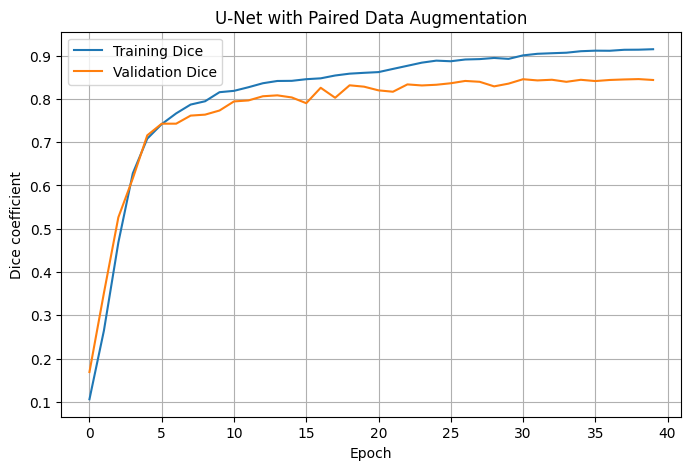

Best validation Dice: 0.8458795547485352
Best epoch: 39
Saved checkpoint: ..\models\segmentation\unet_augmented_best.keras


In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    history_aug.history["dice_coefficient"],
    label="Training Dice"
)
plt.plot(
    history_aug.history["val_dice_coefficient"],
    label="Validation Dice"
)
plt.xlabel("Epoch")
plt.ylabel("Dice coefficient")
plt.title("U-Net with Paired Data Augmentation")
plt.legend()
plt.grid(True)
plt.show()

best_epoch = (
    max(
        range(len(history_aug.history["val_dice_coefficient"])),
        key=lambda i: history_aug.history["val_dice_coefficient"][i]
    ) + 1
)

print("Best validation Dice:",
      max(history_aug.history["val_dice_coefficient"]))
print("Best epoch:", best_epoch)
print("Saved checkpoint:", NEW_MODEL_PATH)

In [86]:
import tensorflow as tf
from pathlib import Path

NEW_MODEL_PATH = Path(
    "../models/segmentation/unet_augmented_best.keras"
)

assert NEW_MODEL_PATH.exists(), (
    f"Model not found: {NEW_MODEL_PATH.resolve()}"
)

best_model = tf.keras.models.load_model(
    NEW_MODEL_PATH,
    custom_objects={
        "combine_loss": combine_loss,
        "dice_coefficient": dice_coefficient,
        "iou_score": iou_score,
    },
    compile=False
)

print("Loaded:", NEW_MODEL_PATH.resolve())
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

Loaded: C:\Projects\BrainTumorAI\models\segmentation\unet_augmented_best.keras
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)


In [87]:
import numpy as np

def calculate_dice(y_true, y_pred, threshold=0.5, smooth=1e-7):
    y_true = np.asarray(y_true) > 0.5
    y_pred = np.asarray(y_pred) >= threshold

    intersection = np.logical_and(y_true, y_pred).sum()
    denominator = y_true.sum() + y_pred.sum()

    return (2.0 * intersection + smooth) / (denominator + smooth)

val_dice_scores = []
missed_cases = []

for batch_images, batch_masks in val_dataset:
    probabilities = best_model.predict(batch_images, verbose=0)
    images_np = batch_images.numpy()
    masks_np = batch_masks.numpy()

    for i in range(len(images_np)):
        gt = masks_np[i]
        prob = probabilities[i]
        pred = prob >= 0.5

        dice = calculate_dice(gt, pred)
        val_dice_scores.append(dice)

        true_pixels = int((gt > 0.5).sum())
        pred_pixels = int(pred.sum())

        if true_pixels > 0 and dice < 0.5:
            missed_cases.append({
                "dice": float(dice),
                "true_pixels": true_pixels,
                "predicted_pixels": pred_pixels,
                "max_probability": float(prob.max()),
                "mean_probability": float(prob.mean()),
                "image": images_np[i],
                "mask": gt,
                "probability_map": prob,
            })

print("Mean validation Dice:", round(float(np.mean(val_dice_scores)), 4))
print("Median validation Dice:", round(float(np.median(val_dice_scores)), 4))
print("Cases with Dice < 0.5:", len(missed_cases))

Mean validation Dice: 0.8482
Median validation Dice: 0.9309
Cases with Dice < 0.5: 52


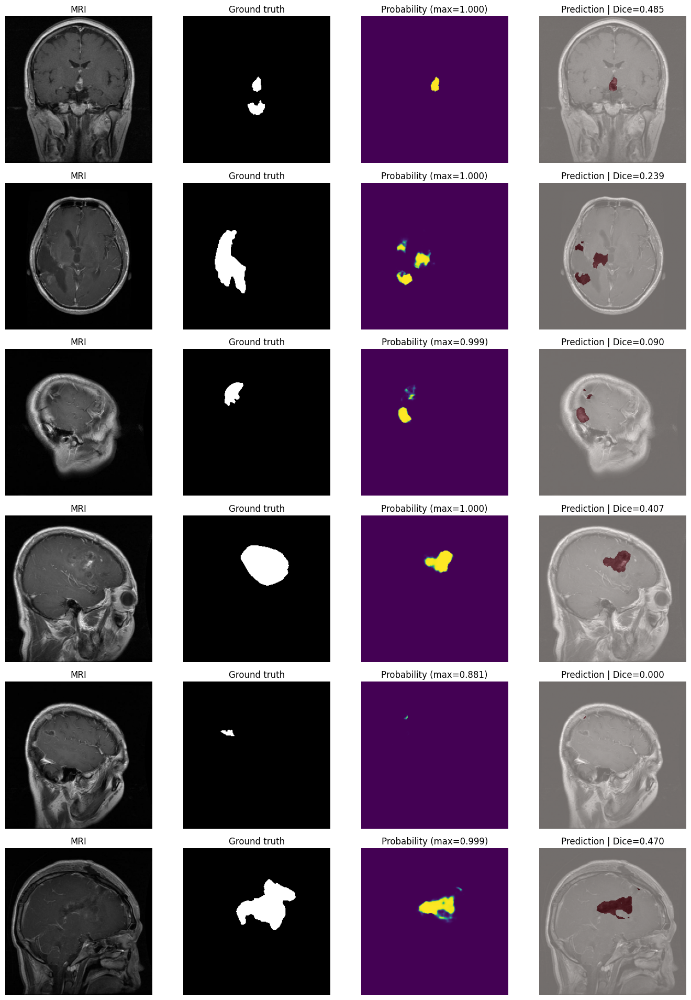

In [88]:
import matplotlib.pyplot as plt

n = min(6, len(missed_cases))

if n == 0:
    print("No validation cases with Dice below 0.5.")
else:
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.2 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, case in enumerate(missed_cases[:n]):
        image = case["image"].squeeze()
        gt = case["mask"].squeeze()
        prob = case["probability_map"].squeeze()
        pred = prob >= 0.5

        axes[row, 0].imshow(image, cmap="gray")
        axes[row, 0].set_title("MRI")

        axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground truth")

        axes[row, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title(
            f"Probability (max={prob.max():.3f})"
        )

        axes[row, 3].imshow(image, cmap="gray")
        axes[row, 3].imshow(
            pred, cmap="Reds", alpha=0.45, vmin=0, vmax=1
        )
        axes[row, 3].set_title(
            f"Prediction | Dice={case['dice']:.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [89]:
import numpy as np
import pandas as pd
import tensorflow as tf

THRESHOLD = 0.5
records = []

for batch_index, (images, masks) in enumerate(val_dataset):
    probabilities = unnet_model.predict(images, verbose=0)

    images_np = images.numpy()
    masks_np = masks.numpy()
    probabilities = np.squeeze(probabilities, axis=-1)
    masks_np = np.squeeze(masks_np, axis=-1)

    for i in range(len(images_np)):
        true_mask = masks_np[i] >= 0.5
        prob_map = probabilities[i]
        pred_mask = prob_map >= THRESHOLD

        intersection = np.logical_and(
            true_mask, pred_mask
        ).sum()

        true_pixels = int(true_mask.sum())
        predicted_pixels = int(pred_mask.sum())

        dice = (
            2.0 * intersection /
            (true_pixels + predicted_pixels)
            if true_pixels + predicted_pixels > 0
            else 1.0
        )

        records.append({
            "index": batch_index * int(images.shape[0]) + i,
            "true_pixels": true_pixels,
            "predicted_pixels": predicted_pixels,
            "max_probability": float(prob_map.max()),
            "mean_probability": float(prob_map.mean()),
            "dice": float(dice),
            "error_type": (
                "missed_tumor"
                if true_pixels > 0 and predicted_pixels == 0
                else "false_positive"
                if true_pixels == 0 and predicted_pixels > 0
                else "poor_overlap"
                if dice < 0.5
                else "acceptable"
            )
        })

failure_df = pd.DataFrame(records)

print("Validation cases:", len(failure_df))
print("\nFailure categories:")
print(failure_df["error_type"].value_counts())

print("\nWorst 20 cases:")
display(
    failure_df.sort_values("dice").head(20)
)

Validation cases: 787

Failure categories:
error_type
acceptable      733
poor_overlap     39
missed_tumor     15
Name: count, dtype: int64

Worst 20 cases:


,index,true_pixels,predicted_pixels,max_probability,mean_probability,dice,error_type
496,496,243,281,0.999272,0.004502,0.0,poor_overlap
202,202,234,0,0.261037,0.000065,0.0,missed_tumor
590,590,508,1898,0.999548,0.029242,0.0,poor_overlap
551,551,1490,62,0.969570,0.001000,0.0,poor_overlap
259,259,944,69,0.988554,0.001250,0.0,poor_overlap
400,400,67,48,0.948314,0.000813,0.0,poor_overlap
114,114,800,2415,0.999487,0.036392,0.0,poor_overlap
653,653,425,0,0.177694,0.000112,0.0,missed_tumor
507,507,780,0,0.154048,0.000052,0.0,missed_tumor
218,218,110,0,0.002142,0.000010,0.0,missed_tumor


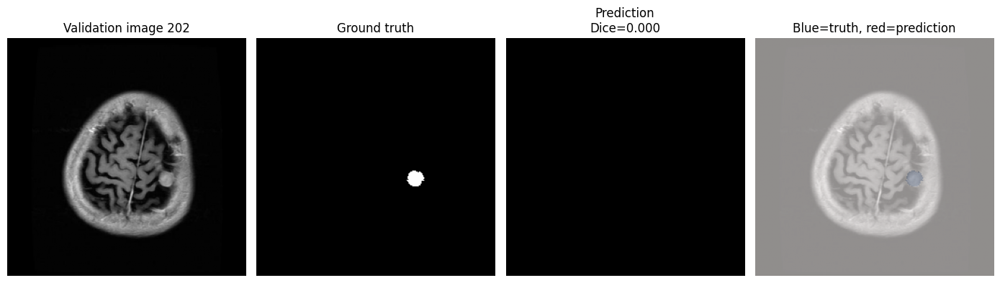

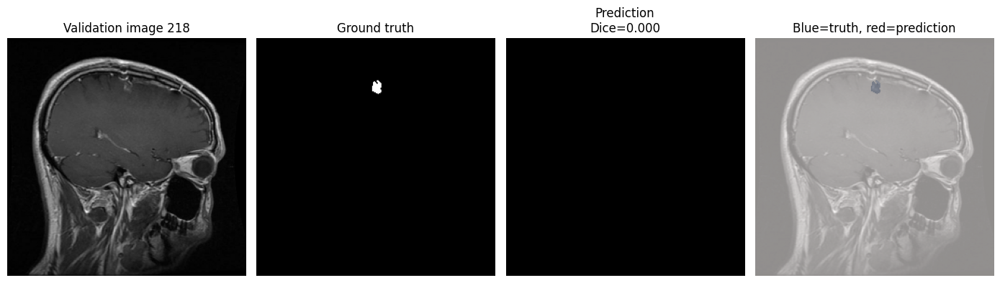

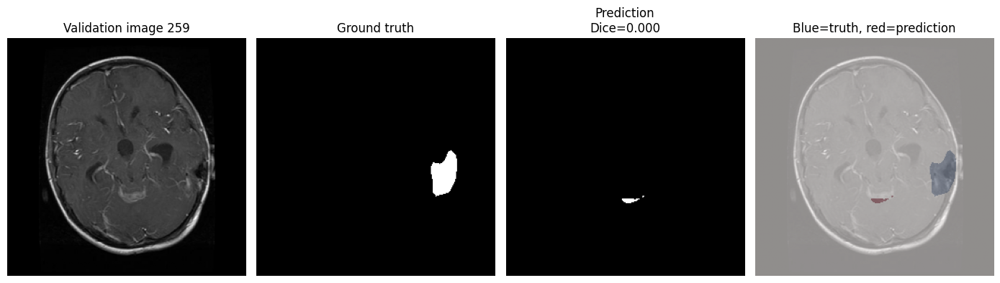

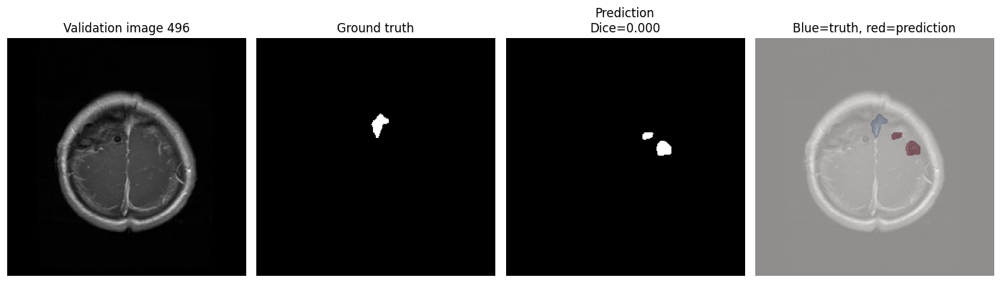

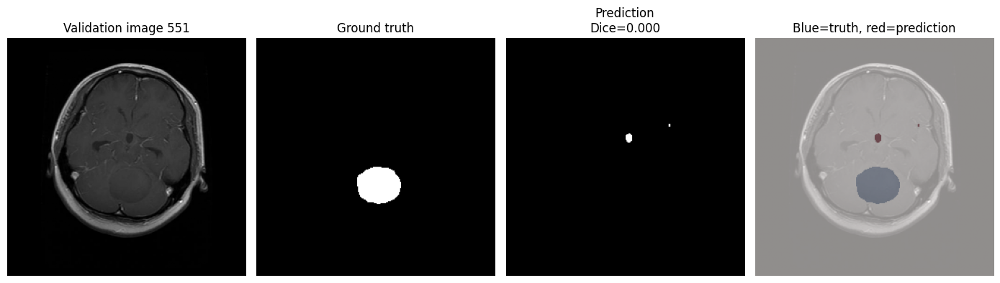

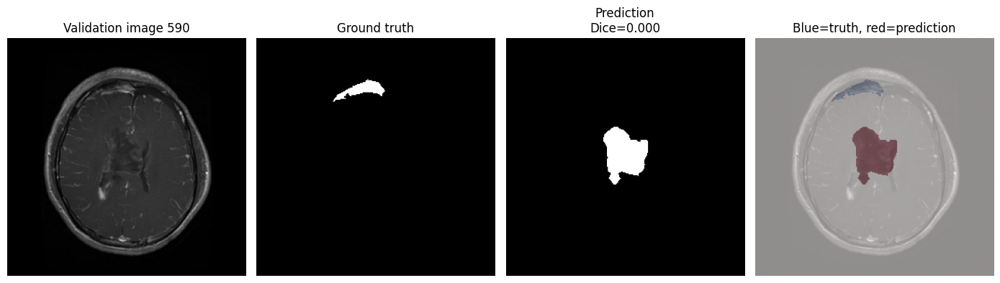

In [90]:
import numpy as np
import matplotlib.pyplot as plt

THRESHOLD = 0.5

# Choose representative cases from your diagnostic table
case_indices = [496, 202, 590, 551, 259, 218]

# Retrieve the selected images from the validation dataset
selected = set(case_indices)
offset = 0

for images, masks in val_dataset:
    batch_size = int(images.shape[0])
    relevant = [
        idx for idx in case_indices
        if offset <= idx < offset + batch_size
    ]

    if relevant:
        probabilities = unnet_model.predict(images, verbose=0)

        for idx in relevant:
            j = idx - offset

            image = images[j].numpy().squeeze()
            true_mask = masks[j].numpy().squeeze() >= 0.5
            prob = probabilities[j].squeeze()
            pred_mask = prob >= THRESHOLD

            intersection = np.logical_and(
                true_mask, pred_mask
            ).sum()

            dice = (
                2 * intersection /
                (true_mask.sum() + pred_mask.sum())
                if true_mask.sum() + pred_mask.sum() > 0
                else 1.0
            )

            fig, ax = plt.subplots(1, 4, figsize=(14, 4))
            ax[0].imshow(image, cmap="gray")
            ax[0].set_title(f"Validation image {idx}")

            ax[1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
            ax[1].set_title("Ground truth")

            ax[2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
            ax[2].set_title(
                f"Prediction\nDice={dice:.3f}"
            )

            ax[3].imshow(image, cmap="gray")
            ax[3].imshow(
                true_mask, cmap="Blues", alpha=0.35
            )
            ax[3].imshow(
                pred_mask, cmap="Reds", alpha=0.35
            )
            ax[3].set_title("Blue=truth, red=prediction")

            for a in ax:
                a.axis("off")

            plt.tight_layout()
            plt.show()

    offset += batch_size

    if offset > max(case_indices):
        break

In [91]:
idx = 496

# Rebuild the prediction for the selected validation index
images_list = []
masks_list = []

for images, masks in val_dataset:
    images_list.append(images.numpy())
    masks_list.append(masks.numpy())

all_images = np.concatenate(images_list, axis=0)
all_masks = np.concatenate(masks_list, axis=0)

prob = unnet_model.predict(
    all_images[idx:idx + 1],
    verbose=0
)[0, :, :, 0]

truth = all_masks[idx, :, :, 0] >= 0.5
pred = prob >= 0.5

intersection = np.logical_and(truth, pred).sum()
union = np.logical_or(truth, pred).sum()

print("Index:", idx)
print("True pixels:", int(truth.sum()))
print("Predicted pixels:", int(pred.sum()))
print("Intersection:", int(intersection))
print("Union:", int(union))
print("Dice:", 2 * intersection / (truth.sum() + pred.sum() + 1e-7))
print("IoU:", intersection / (union + 1e-7))

Index: 496
True pixels: 243
Predicted pixels: 281
Intersection: 0
Union: 524
Dice: 0.0
IoU: 0.0


Image shape: (256, 256)
True tumor pixels: 243
Predicted pixels: 281
Intersection: 0
Probability min/max: 8.622456637574771e-10 0.9992720484733582
Dice: 0.0


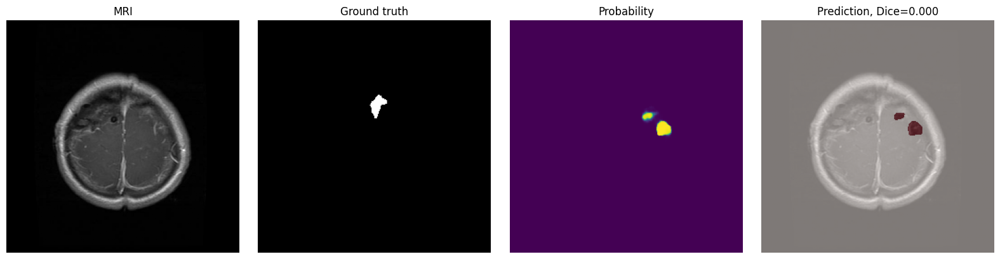

In [92]:
import numpy as np
import matplotlib.pyplot as plt

# Use the exact validation example
idx = 496

# Load the image and ground-truth mask from the validation dataset.
# This assumes val_dataset yields (images, masks).
images, masks = next(iter(val_dataset.skip(idx // BATCH_SIZE)))
offset = idx % BATCH_SIZE

image = images[offset].numpy().squeeze()
true_mask = masks[offset].numpy().squeeze() >= 0.5

# Predict using the saved/best model variable.
prob_map = unnet_model.predict(
    images[offset:offset + 1],
    verbose=0
)[0].squeeze()

threshold = 0.5
pred_mask = prob_map >= threshold

intersection = np.logical_and(true_mask, pred_mask).sum()
dice = (
    2 * intersection /
    (true_mask.sum() + pred_mask.sum() + 1e-7)
)

print("Image shape:", image.shape)
print("True tumor pixels:", int(true_mask.sum()))
print("Predicted pixels:", int(pred_mask.sum()))
print("Intersection:", int(intersection))
print("Probability min/max:", float(prob_map.min()),
      float(prob_map.max()))
print("Dice:", float(dice))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("MRI")
axes[1].imshow(true_mask, cmap="gray")
axes[1].set_title("Ground truth")
axes[2].imshow(prob_map, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Probability")
axes[3].imshow(image, cmap="gray")
axes[3].imshow(pred_mask, cmap="Reds", alpha=0.5)
axes[3].set_title(f"Prediction, Dice={dice:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()